In [1]:
!pip install mysql-connector-python

In [39]:
import mysql.connector

mydb = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="urban_pulse_db"
)

print(mydb.is_connected())

True


In [11]:
mycursor = mydb.cursor(buffered=True)

In [12]:
mycursor.execute("SHOW DATABASES")

for x in mycursor:
    print(x)

('aiml_we_b19',)
('guvi',)
('information_schema',)
('mysql',)
('performance_schema',)
('phpmyadmin',)
('test',)
('urban_pulse_db',)


In [38]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="urban_pulse_db"
)

print(conn.is_connected())

True


In [ ]:
Investigation 1: Top 10 Complaint Categories

In [14]:
import pandas as pd

query = """
SELECT complaint_type, COUNT(*) AS total
FROM service_requests
GROUP BY complaint_type
ORDER BY total DESC
LIMIT 10;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2713927804.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,complaint_type,total
0,Noise - Residential,2416
1,Illegal Parking,1578
2,Noise - Street/Sidewalk,860
3,HEAT/HOT WATER,638
4,Blocked Driveway,522
5,Noise - Commercial,462
6,UNSANITARY CONDITION,205
7,Noise,175
8,Noise - Vehicle,150
9,Water Maintenance,149


In [ ]:
Agency Workload Distribution

In [6]:
query = """
SELECT agency,
       COUNT(*) AS total
FROM service_requests
GROUP BY agency
ORDER BY total DESC;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3369185151.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,agency,total
0,NYPD,6367
1,HPD,1493
2,DSNY,475
3,DEP,425
4,DOT,348
5,DOB,181
6,DPR,175
7,DOHMH,164
8,DHS,164
9,TLC,145


In [ ]:
Which agencies receive the highest number of service requests?

In [17]:
query = """
SELECT complaint_type, COUNT(*) AS total
FROM service_requests
GROUP BY complaint_type
ORDER BY total DESC
LIMIT 10;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3945062256.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,complaint_type,total
0,Noise - Residential,2416
1,Illegal Parking,1578
2,Noise - Street/Sidewalk,860
3,HEAT/HOT WATER,638
4,Blocked Driveway,522
5,Noise - Commercial,462
6,UNSANITARY CONDITION,205
7,Noise,175
8,Noise - Vehicle,150
9,Water Maintenance,149


In [ ]:
Borough Distribution

In [18]:
query = """
SELECT borough,
       COUNT(*) AS total
FROM service_requests
GROUP BY borough
ORDER BY total DESC;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\1866505418.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,borough,total
0,BROOKLYN,3119
1,MANHATTAN,2566
2,QUEENS,2292
3,BRONX,1591
4,STATEN ISLAND,422
5,Unspecified,10


In [ ]:
Status Distribution

In [20]:
query = """
SELECT status,
       COUNT(*) AS total
FROM service_requests
GROUP BY status
ORDER BY total DESC;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\344039615.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,status,total
0,Closed,4922
1,In Progress,3361
2,Open,1701
3,Assigned,15
4,Unspecified,1


In [ ]:
Distribution of Recorded Request Statuses

In [23]:
query = """
SELECT status,
       COUNT(*) AS total
FROM service_requests
GROUP BY status
ORDER BY total DESC;
"""

df = pd.read_sql(query, conn)
df

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\344039615.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,status,total
0,Closed,4922
1,In Progress,3361
2,Open,1701
3,Assigned,15
4,Unspecified,1


In [ ]:
Monthly Request Trend

In [24]:
query = """
SELECT MONTH(created_date) AS month_num,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY MONTH(created_date)
ORDER BY month_num;
"""

monthly_trend = pd.read_sql(query, conn)
monthly_trend

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3035696515.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly_trend = pd.read_sql(query, conn)


,month_num,total_requests
0,10,8460
1,11,1540


In [ ]:
Demand by Weekday

In [26]:
query = """
SHOW COLUMNS FROM service_requests;
"""

pd.read_sql(query, conn)


C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2696260022.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,Field,Type,Null,Key,Default,Extra
0,unique_key,int(8),YES,,None,
1,created_date,varchar(23),YES,,None,
2,agency,varchar(5),YES,,None,
3,complaint_type,varchar(39),YES,,None,
4,descriptor,varchar(80),YES,,None,
5,borough,varchar(13),YES,,None,
6,status,varchar(11),YES,,None,
7,latitude,varchar(18),YES,,None,
8,longitude,varchar(18),YES,,None,
9,closed_date,varchar(23),YES,,None,


In [ ]:
Closure Rate Comparison

In [27]:
query = """
SELECT
    status,
    COUNT(*) AS total_requests,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM service_requests),
        2
    ) AS percentage
FROM service_requests
GROUP BY status
ORDER BY total_requests DESC;
"""

closure_rate = pd.read_sql(query, conn)
closure_rate

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\1293226376.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  closure_rate = pd.read_sql(query, conn)


,status,total_requests,percentage
0,Closed,4922,49.22
1,In Progress,3361,33.61
2,Open,1701,17.01
3,Assigned,15,0.15
4,Unspecified,1,0.01


In [ ]:
Geographic Complaint Concentration

In [28]:
query = """
SELECT borough,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY borough
ORDER BY total_requests DESC;
"""

geo_concentration = pd.read_sql(query, conn)
geo_concentration

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\1494075278.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  geo_concentration = pd.read_sql(query, conn)


,borough,total_requests
0,BROOKLYN,3119
1,MANHATTAN,2566
2,QUEENS,2292
3,BRONX,1591
4,STATEN ISLAND,422
5,Unspecified,10


In [ ]:
Total Distinct Request Volume

In [29]:
query = """
SELECT
    COUNT(*) AS total_requests,
    COUNT(DISTINCT unique_key) AS distinct_requests
FROM service_requests;
"""

request_volume = pd.read_sql(query, conn)
request_volume

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3826466994.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  request_volume = pd.read_sql(query, conn)


,total_requests,distinct_requests
0,10000,10000


In [ ]:
Demand by Complaint Type and Borough

In [30]:
query = """
SELECT borough,
       complaint_type,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY borough, complaint_type
ORDER BY total_requests DESC
LIMIT 20;
"""

borough_complaints = pd.read_sql(query, conn)
borough_complaints

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\416935664.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  borough_complaints = pd.read_sql(query, conn)


,borough,complaint_type,total_requests
0,BROOKLYN,Noise - Residential,867
1,MANHATTAN,Noise - Residential,643
2,BROOKLYN,Illegal Parking,605
3,QUEENS,Illegal Parking,500
4,QUEENS,Noise - Residential,459
5,MANHATTAN,Noise - Street/Sidewalk,380
6,BRONX,Noise - Residential,335
7,QUEENS,Blocked Driveway,238
8,MANHATTAN,Illegal Parking,221
9,BRONX,Illegal Parking,218


In [ ]:
Demand by Agency and Borough

In [31]:
query = """
SELECT borough,
       agency,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY borough, agency
ORDER BY total_requests DESC
LIMIT 20;
"""

agency_borough = pd.read_sql(query, conn)
agency_borough

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\1945466624.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  agency_borough = pd.read_sql(query, conn)


,borough,agency,total_requests
0,BROOKLYN,NYPD,2144
1,QUEENS,NYPD,1592
2,MANHATTAN,NYPD,1590
3,BRONX,NYPD,838
4,BRONX,HPD,519
5,BROOKLYN,HPD,403
6,MANHATTAN,HPD,360
7,STATEN ISLAND,NYPD,203
8,QUEENS,HPD,184
9,BROOKLYN,DSNY,129


In [ ]:
Top Complaint Types by Agency

In [32]:
query = """
SELECT agency,
       complaint_type,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY agency, complaint_type
ORDER BY total_requests DESC
LIMIT 20;
"""

agency_complaints = pd.read_sql(query, conn)
agency_complaints

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2819642319.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  agency_complaints = pd.read_sql(query, conn)


,agency,complaint_type,total_requests
0,NYPD,Noise - Residential,2416
1,NYPD,Illegal Parking,1578
2,NYPD,Noise - Street/Sidewalk,860
3,HPD,HEAT/HOT WATER,638
4,NYPD,Blocked Driveway,522
5,NYPD,Noise - Commercial,462
6,HPD,UNSANITARY CONDITION,205
7,DEP,Noise,175
8,NYPD,Noise - Vehicle,150
9,DEP,Water Maintenance,149


In [ ]:
Highest number of Closed, Open, and In Progress requests.

In [33]:
query = """
SELECT agency,
       status,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY agency, status
ORDER BY total_requests DESC
LIMIT 20;
"""

agency_status = pd.read_sql(query, conn)
agency_status

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3962013506.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  agency_status = pd.read_sql(query, conn)


,agency,status,total_requests
0,NYPD,Closed,4508
1,NYPD,In Progress,1859
2,HPD,Open,1391
3,DEP,In Progress,385
4,DSNY,In Progress,383
5,DOB,Open,179
6,DOHMH,In Progress,163
7,DPR,In Progress,158
8,DOT,In Progress,158
9,TLC,In Progress,145


In [ ]:
Descriptor Analysis (Most Common Detailed Complaint Descriptions)

In [34]:
query = """
SELECT descriptor,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY descriptor
ORDER BY total_requests DESC
LIMIT 20;
"""

descriptor_analysis = pd.read_sql(query, conn)
descriptor_analysis

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3294474299.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  descriptor_analysis = pd.read_sql(query, conn)


,descriptor,total_requests
0,Loud Music/Party,2953
1,Blocked Hydrant,542
2,Banging/Pounding,486
3,ENTIRE BUILDING,463
4,No Access,393
5,Posted Parking Sign Violation,354
6,Loud Talking,297
7,Blocked Sidewalk,216
8,APARTMENT ONLY,175
9,With License Plate,134


In [ ]:
Median Resolution Time by Complaint Type

In [44]:
df = pd.read_csv("nyc_311_cleaned.csv")

In [45]:
for col in df.columns:
    print(col)

unique_key
created_date
agency
complaint_type
descriptor
borough
status
latitude
longitude
closed_date


In [46]:
df.shape

(10000, 10)

In [47]:
'resolution_hours' in df.columns

False

In [48]:
df['created_date'] = pd.to_datetime(df['created_date'])
df['closed_date'] = pd.to_datetime(df['closed_date'])

df['resolution_hours'] = (
    df['closed_date'] - df['created_date']
).dt.total_seconds() / 3600


In [49]:
df.groupby('complaint_type')['resolution_hours'] \
  .median() \
  .sort_values(ascending=False) \
  .head(10)

complaint_type
Derelict Vehicles             10.533333
Encampment                     9.437500
GENERAL                        8.035556
PAINT/PLASTER                  7.855556
UNSANITARY CONDITION           7.855556
SAFETY                         7.783333
HEAT/HOT WATER                 7.348889
WATER LEAK                     6.930972
Dirty Condition                6.606944
Homeless Person Assistance     6.163056
Name: resolution_hours, dtype: float64

In [ ]:
Monthly Request Trend

In [58]:
query = """
SELECT
    MONTH(created_date) AS month,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY MONTH(created_date)
ORDER BY month;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2472271262.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,month,total_requests
0,10,8460
1,11,1540


In [ ]:
Demand by Weekday

In [59]:
query = """
SELECT
    DAYNAME(created_date) AS weekday,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY DAYNAME(created_date)
ORDER BY total_requests DESC;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\751011926.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,weekday,total_requests
0,Saturday,8460
1,Sunday,1540


In [ ]:
Demand by Hour

In [60]:
query = """
SELECT
    HOUR(created_date) AS hour,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY HOUR(created_date)
ORDER BY hour;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3038558968.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,hour,total_requests
0,0,700
1,1,812
2,2,28
3,8,395
4,9,556
5,10,571
6,11,488
7,12,566
8,13,486
9,14,420


In [ ]:
Resolution Time by Agency

In [61]:
query = """
SELECT
    agency,
    ROUND(
        AVG(
            TIMESTAMPDIFF(HOUR, created_date, closed_date)
        ),2
    ) AS avg_resolution_hours
FROM service_requests
WHERE closed_date IS NOT NULL
GROUP BY agency
ORDER BY avg_resolution_hours DESC;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3476698929.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,agency,avg_resolution_hours
0,DHS,7.59
1,HPD,6.42
2,DSNY,1.88
3,DOT,1.26
4,DPR,1.24
5,NYPD,1.19
6,DEP,0.33
7,DOHMH,0.00
8,DOB,0.00
9,OOS,NaN


In [ ]:
IQR-Based Outlier Investigation

In [62]:
Q1 = df['resolution_hours'].quantile(0.25)
Q3 = df['resolution_hours'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['resolution_hours'] < lower_bound) |
    (df['resolution_hours'] > upper_bound)
]

print("Number of Outliers:", len(outliers))

Q1: 0.3945833333333333
Q3: 2.176458333333333
IQR: 1.7818749999999999
Lower Bound: -2.2782291666666667
Upper Bound: 4.849270833333334
Number of Outliers: 542


In [ ]:
Resolution Time Distribution & Skewness

In [63]:
print("Skewness:",
      df['resolution_hours'].skew())

Skewness: 2.350928041343306


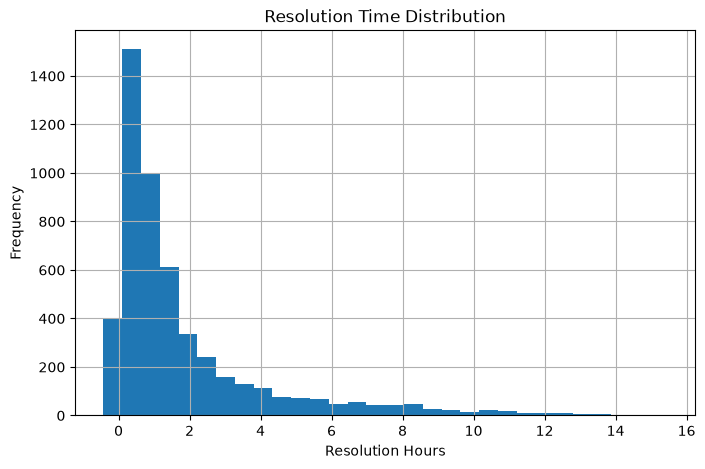

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df['resolution_hours'].hist(bins=30)

plt.title('Resolution Time Distribution')
plt.xlabel('Resolution Hours')
plt.ylabel('Frequency')

plt.show()

In [ ]:
Closure Rate Comparison

In [65]:
query = """
SELECT
    status,
    COUNT(*) AS request_count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM service_requests),
        2
    ) AS percentage
FROM service_requests
GROUP BY status
ORDER BY request_count DESC;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\1719746584.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,status,request_count,percentage
0,Closed,4922,49.22
1,In Progress,3361,33.61
2,Open,1701,17.01
3,Assigned,15,0.15
4,Unspecified,1,0.01


In [ ]:
Overall Closure Rate

In [66]:
query = """
SELECT
    ROUND(
        SUM(CASE WHEN status = 'Closed' THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*),
        2
    ) AS closure_rate
FROM service_requests;
"""

pd.read_sql(query, conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\698658614.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, conn)


,closure_rate
0,49.22


In [ ]:
High Volume + Long Resolution Time

In [67]:
summary = df.groupby('complaint_type').agg(
{
    'unique_key':'count',
    'resolution_hours':'median'
}
)

summary.columns = [
    'request_count',
    'median_resolution_hours'
]

summary.sort_values(
    by=['request_count',
        'median_resolution_hours'],
    ascending=False
).head(10)

,request_count,median_resolution_hours
complaint_type,,
Noise - Residential,2416,0.791667
Illegal Parking,1578,1.110972
Noise - Street/Sidewalk,860,0.816111
HEAT/HOT WATER,638,7.348889
Blocked Driveway,522,1.771250
Noise - Commercial,462,0.629167
UNSANITARY CONDITION,205,7.855556
Noise,175,0.827778
Noise - Vehicle,150,0.840000


In [ ]:
IQR Outlier Investigation

In [68]:
Q1 = df['resolution_hours'].quantile(0.25)
Q3 = df['resolution_hours'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['resolution_hours'] < lower_bound) |
    (df['resolution_hours'] > upper_bound)
]

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)
print("Number of Outliers =", len(outliers))

Q1 = 0.3945833333333333
Q3 = 2.176458333333333
IQR = 1.7818749999999999
Lower Bound = -2.2782291666666667
Upper Bound = 4.849270833333334
Number of Outliers = 542


In [ ]:
Skewness Analysis

In [69]:
df['resolution_hours'].skew()

np.float64(2.350928041343306)

In [ ]:
Histogram

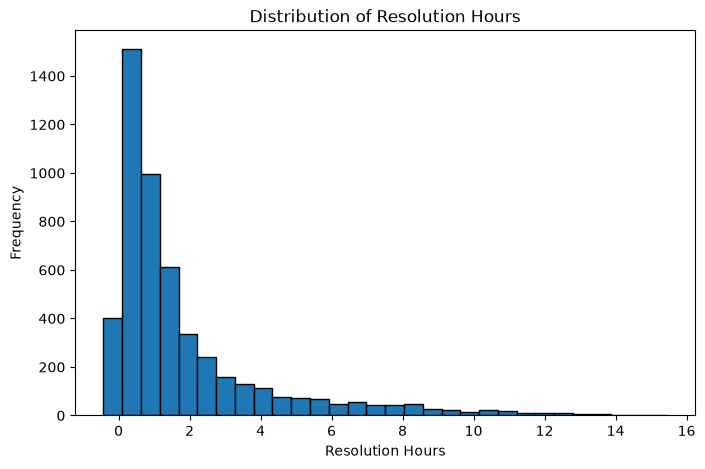

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df['resolution_hours'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Resolution Hours')
plt.xlabel('Resolution Hours')
plt.ylabel('Frequency')

plt.show()

In [ ]:
Boxplot

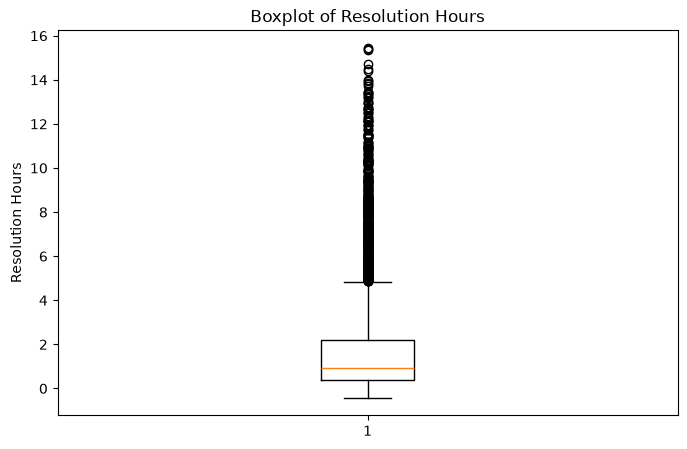

In [71]:
plt.figure(figsize=(8,5))

plt.boxplot(
    df['resolution_hours'].dropna()
)

plt.title('Boxplot of Resolution Hours')
plt.ylabel('Resolution Hours')

plt.show()

In [ ]:
agency_workload

In [81]:
agency_workload = pd.read_sql("""
SELECT
    agency,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY agency
ORDER BY total_requests DESC;
""", conn)

agency_workload.head()

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3962849623.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  agency_workload = pd.read_sql("""


,agency,total_requests
0,NYPD,6367
1,HPD,1493
2,DSNY,475
3,DEP,425
4,DOT,348


In [77]:
total_requests = pd.read_sql("""
SELECT COUNT(*) AS total_requests
FROM service_requests;
""", conn)

top_complaints = pd.read_sql("""
SELECT complaint_type,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY complaint_type
ORDER BY total_requests DESC
LIMIT 10;
""", conn)

with pd.ExcelWriter("UrbanPulse_SQL_Results.xlsx") as writer:
    total_requests.to_excel(
        writer,
        sheet_name="Total_Requests",
        index=False
    )

    top_complaints.to_excel(
        writer,
        sheet_name="Top_Complaints",
        index=False
    )

print("Saved Successfully")

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2763407757.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  total_requests = pd.read_sql("""
C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2763407757.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_complaints = pd.read_sql("""


Saved Successfully


In [78]:
import os

print(os.getcwd())

C:\Users\gaaya\Downloads


In [82]:
import pandas as pd

with pd.ExcelWriter("UrbanPulse_SQL_Results.xlsx", engine="openpyxl") as writer:

    total_requests.to_excel(
        writer,
        sheet_name="Task1_TotalRequests",
        index=False
    )

    top_complaints.to_excel(
        writer,
        sheet_name="Task2_TopComplaints",
        index=False
    )

    agency_workload.to_excel(
        writer,
        sheet_name="Task3_AgencyWorkload",
        index=False
    )

    borough_analysis.to_excel(
        writer,
        sheet_name="Task4_Borough",
        index=False
    )

    monthly_trend.to_excel(
        writer,
        sheet_name="Task5_MonthlyTrend",
        index=False
    )

    weekday_demand.to_excel(
        writer,
        sheet_name="Task6_WeekdayDemand",
        index=False
    )

    hourly_demand.to_excel(
        writer,
        sheet_name="Task7_HourlyDemand",
        index=False
    )

    status_distribution.to_excel(
        writer,
        sheet_name="Task8_Status",
        index=False
    )

    resolution_stats.to_excel(
        writer,
        sheet_name="Task9_ResolutionStats",
        index=False
    )

    resolution_by_complaint.to_excel(
        writer,
        sheet_name="Task10_ComplaintRes",
        index=False
    )

    resolution_by_agency.to_excel(
        writer,
        sheet_name="Task11_AgencyRes",
        index=False
    )

    outliers.to_excel(
        writer,
        sheet_name="Task12_Outliers",
        index=False
    )

    geo_concentration.to_excel(
        writer,
        sheet_name="Task13_Geographic",
        index=False
    )

    closure_rate.to_excel(
        writer,
        sheet_name="Task14_ClosureRate",
        index=False
    )

    high_volume_long_resolution.to_excel(
        writer,
        sheet_name="Task15_HighVolume",
        index=False
    )

print("✅ UrbanPulse_SQL_Results.xlsx saved successfully!")


NameError: name 'borough_analysis' is not defined

In [ ]:
borough_analysis

In [83]:
borough_analysis = pd.read_sql("""
SELECT
    borough,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY borough
ORDER BY total_requests DESC;
""", conn)

borough_analysis

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3253745575.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  borough_analysis = pd.read_sql("""


,borough,total_requests
0,BROOKLYN,3119
1,MANHATTAN,2566
2,QUEENS,2292
3,BRONX,1591
4,STATEN ISLAND,422
5,Unspecified,10


In [ ]:
# Task 1
total_requests = pd.read_sql("""
SELECT COUNT(*) AS total_requests
FROM service_requests;
""", conn)

# Task 2
top_complaints = pd.read_sql("""
SELECT complaint_type,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY complaint_type
ORDER BY total_requests DESC
LIMIT 10;
""", conn)

# Task 3
agency_workload = pd.read_sql("""
SELECT agency,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY agency
ORDER BY total_requests DESC;
""", conn)

# Task 4
borough_analysis = pd.read_sql("""
SELECT borough,
       COUNT(*) AS total_requests
FROM service_requests
GROUP BY borough
ORDER BY total_requests DESC;
""", conn)

In [84]:
%whos DataFrame

Variable              Type         Data/Info
--------------------------------------------
agency_borough        DataFrame    Shape: (20, 3)
agency_complaints     DataFrame    Shape: (20, 3)
agency_status         DataFrame    Shape: (20, 3)
agency_workload       DataFrame    Shape: (13, 2)
borough_analysis      DataFrame    Shape: (6, 2)
borough_complaints    DataFrame    Shape: (20, 3)
closure_rate          DataFrame    Shape: (5, 3)
descriptor_analysis   DataFrame    Shape: (20, 2)
df                    DataFrame    Shape: (10000, 11)
geo_concentration     DataFrame    Shape: (6, 2)
monthly_trend         DataFrame    Shape: (2, 2)
outliers              DataFrame    Shape: (542, 11)
request_volume        DataFrame    Shape: (1, 2)
result                DataFrame    Shape: (1, 1)
summary               DataFrame    Shape: (124, 2)
top_complaints        DataFrame    Shape: (10, 2)
total_requests        DataFrame    Shape: (1, 1)


In [85]:
import pandas as pd

with pd.ExcelWriter(
    r"C:\Users\gaaya\Downloads\UrbanPulse_SQL_Results.xlsx",
    engine="openpyxl"
) as writer:

    total_requests.to_excel(writer,
                            sheet_name="Task1_TotalRequests",
                            index=False)

    top_complaints.to_excel(writer,
                            sheet_name="Task2_TopComplaints",
                            index=False)

    agency_workload.to_excel(writer,
                             sheet_name="Task3_AgencyWorkload",
                             index=False)

    borough_analysis.to_excel(writer,
                              sheet_name="Task4_BoroughAnalysis",
                              index=False)

    monthly_trend.to_excel(writer,
                           sheet_name="Task5_MonthlyTrend",
                           index=False)

    closure_rate.to_excel(writer,
                          sheet_name="Task14_ClosureRate",
                          index=False)

    geo_concentration.to_excel(writer,
                               sheet_name="Task13_Geographic",
                               index=False)

    outliers.to_excel(writer,
                      sheet_name="Task12_Outliers",
                      index=False)

    summary.to_excel(writer,
                     sheet_name="Task15_HighVolume",
                     index=True)

print("✅ Excel file saved successfully!")

✅ Excel file saved successfully!


In [ ]:
Weekday Demand

In [93]:
weekday_demand = pd.read_sql("""
SELECT
    DAYNAME(created_date) AS weekday,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY DAYNAME(created_date);
""", conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2506701688.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  weekday_demand = pd.read_sql("""


In [88]:
weekday_demand.head()

,weekday,total_requests
0,Saturday,8460
1,Sunday,1540


In [ ]:
Hourly Demand

In [94]:
hourly_demand = pd.read_sql("""
SELECT
    HOUR(created_date) AS hour,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY HOUR(created_date);
""", conn)


C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\2621301920.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  hourly_demand = pd.read_sql("""


In [95]:
hourly_demand.head()

,hour,total_requests
0,0,700
1,1,812
2,2,28
3,8,395
4,9,556


In [ ]:
status_distribution

In [96]:
status_distribution = pd.read_sql("""
SELECT
    status,
    COUNT(*) AS total_requests
FROM service_requests
GROUP BY status;
""", conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\3104077594.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  status_distribution = pd.read_sql("""


In [97]:
status_distribution.head()

,status,total_requests
0,Assigned,15
1,Closed,4922
2,In Progress,3361
3,Open,1701
4,Unspecified,1


In [ ]:
Resolution by Agency

In [98]:
resolution_by_agency = pd.read_sql("""
SELECT
    agency,
    ROUND(
        AVG(
            TIMESTAMPDIFF(HOUR, created_date, closed_date)
        ),2
    ) AS avg_resolution_hours
FROM service_requests
WHERE closed_date IS NOT NULL
GROUP BY agency
ORDER BY avg_resolution_hours DESC;
""", conn)

C:\Users\gaaya\AppData\Local\Temp\ipykernel_24344\178403446.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  resolution_by_agency = pd.read_sql("""


In [99]:
resolution_by_agency.head()

,agency,avg_resolution_hours
0,DHS,7.59
1,HPD,6.42
2,DSNY,1.88
3,DOT,1.26
4,DPR,1.24


In [ ]:
Resolution by Complaint

In [101]:
resolution_by_complaint = (
    df.groupby('complaint_type')['resolution_hours']
      .median()
      .sort_values(ascending=False)
      .reset_index()
)

In [102]:
resolution_by_complaint.head()

,complaint_type,resolution_hours
0,Derelict Vehicles,10.533333
1,Encampment,9.437500
2,GENERAL,8.035556
3,PAINT/PLASTER,7.855556
4,UNSANITARY CONDITION,7.855556


In [ ]:
resolution_stats

In [108]:
resolution_stats = df['resolution_hours'].describe().reset_index()
resolution_stats.columns = ['Metric', 'Value']
print(resolution_stats)

  Metric        Value
0  count  5116.000000
1   mean     1.854806
2    std     2.419474
3    min    -0.428333
4    25%     0.394583
5    50%     0.919167
6    75%     2.176458
7    max    15.448056


In [109]:
%whos DataFrame

Variable                  Type         Data/Info
------------------------------------------------
agency_borough            DataFrame    Shape: (20, 3)
agency_complaints         DataFrame    Shape: (20, 3)
agency_status             DataFrame    Shape: (20, 3)
agency_workload           DataFrame    Shape: (13, 2)
borough_analysis          DataFrame    Shape: (6, 2)
borough_complaints        DataFrame    Shape: (20, 3)
closure_rate              DataFrame    Shape: (5, 3)
descriptor_analysis       DataFrame    Shape: (20, 2)
df                        DataFrame    Shape: (10000, 11)
geo_concentration         DataFrame    Shape: (6, 2)
hourly_demand             DataFrame    Shape: (19, 2)
monthly_trend             DataFrame    Shape: (2, 2)
outliers                  DataFrame    Shape: (542, 11)
request_volume            DataFrame    Shape: (1, 2)
resolution_by_agency      DataFrame    Shape: (13, 2)
resolution_by_complaint   DataFrame    Shape: (124, 2)
resolution_stats          DataFrame 

In [110]:
with pd.ExcelWriter(
    r"C:\Users\gaaya\Downloads\UrbanPulse_SQL_Results.xlsx",
    engine="openpyxl"
) as writer:

    total_requests.to_excel(writer, sheet_name="Task1_TotalRequests", index=False)

    top_complaints.to_excel(writer, sheet_name="Task2_TopComplaints", index=False)

    agency_workload.to_excel(writer, sheet_name="Task3_AgencyWorkload", index=False)

    borough_analysis.to_excel(writer, sheet_name="Task4_BoroughAnalysis", index=False)

    monthly_trend.to_excel(writer, sheet_name="Task5_MonthlyTrend", index=False)

    weekday_demand.to_excel(writer, sheet_name="Task6_WeekdayDemand", index=False)

    hourly_demand.to_excel(writer, sheet_name="Task7_HourlyDemand", index=False)

    status_distribution.to_excel(writer, sheet_name="Task8_StatusDistribution", index=False)

    resolution_stats.to_excel(writer, sheet_name="Task9_ResolutionStats", index=False)

    resolution_by_complaint.to_excel(writer, sheet_name="Task10_ByComplaint", index=False)

    resolution_by_agency.to_excel(writer, sheet_name="Task11_ByAgency", index=False)

    outliers.to_excel(writer, sheet_name="Task12_Outliers", index=False)

    geo_concentration.to_excel(writer, sheet_name="Task13_Geographic", index=False)

    closure_rate.to_excel(writer, sheet_name="Task14_ClosureRate", index=False)

    summary.to_excel(writer, sheet_name="Task15_HighVolumeLongRes", index=True)

print("✅ UrbanPulse_SQL_Results.xlsx saved successfully!")

Exception ignored while calling deallocator <function ZipFile.__del__ at 0x0000023516714930>:
Traceback (most recent call last):
  File "C:\Users\gaaya\anaconda3\Lib\zipfile\__init__.py", line 2078, in __del__
    self.close()
  File "C:\Users\gaaya\anaconda3\Lib\zipfile\__init__.py", line 2095, in close
    self.fp.seek(self.start_dir)
ValueError: seek of closed file


✅ UrbanPulse_SQL_Results.xlsx saved successfully!


In [111]:
import os

os.path.exists(
    r"C:\Users\gaaya\Downloads\UrbanPulse_SQL_Results.xlsx"
)

True

Create app.py in VS Code

In [ ]:
import streamlit as st
import pandas as pd

df = pd.read_csv("nyc_311_cleaned.csv")

st.title("Urban Pulse NYC Dashboard")

# KPI 1
st.metric("Total Requests", len(df))

# KPI 2
closed = (df['status'] == 'Closed').sum()
closure_rate = round((closed / len(df)) * 100, 2)

st.metric("Closure Rate (%)", closure_rate)

# KPI 3
open_requests = len(df) - closed

st.metric("Open Requests", open_requests)

# KPI 4
median_resolution = round(
    df['resolution_hours'].median(),2
)

st.metric(
    "Median Resolution Hours",
    median_resolution
)

# KPI 5
over72 = round(
    (df['resolution_hours'] > 72).mean() * 100,
    2
)

st.metric("Over 72 Hours (%)", over72)

Add Charts

Top Complaint Types

In [ ]:
st.subheader("Top Complaint Types")

st.bar_chart(
    df['complaint_type']
      .value_counts()
      .head(10)
)